In [21]:
import pandas as pd, numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

from common import load_split, build_preprocess

X_train, X_test, y_train, y_test = load_split()
print(X_train.shape, X_test.shape)

(242, 13) (61, 13)


In [22]:
models = {
    "Dummy (baseline)":    DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=42),
}

pipelines = {
    name: Pipeline([("prep", build_preprocess()), ("model", model)])
    for name, model in models.items()
}

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "recall", "accuracy"]

rows = []
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "AUC":      res["test_roc_auc"].mean(),
        "AUC_std":  res["test_roc_auc"].std(),
        "recall":   res["test_recall"].mean(),
        "accuracy": res["test_accuracy"].mean(),
    })

results = pd.DataFrame(rows).sort_values("AUC", ascending=False).round(3)
results

,model,AUC,AUC_std,recall,accuracy
1,Logistic Regression,0.902,0.014,0.783,0.847
5,Random Forest,0.894,0.033,0.801,0.814
3,SVM,0.888,0.024,0.765,0.814
2,KNN,0.872,0.031,0.766,0.818
6,Gradient Boosting,0.857,0.018,0.792,0.798
4,Decision Tree,0.786,0.026,0.674,0.727
0,Dummy (baseline),0.500,0.000,0.000,0.541


In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt

top3 = [m for m in results["model"] if m != "Dummy (baseline)"][:3]
print("۳ مدل برتر:", top3)

oof = {}
for name in top3:
    oof[name] = cross_val_predict(pipelines[name], X_train, y_train,
                                  cv=cv, method="predict_proba")[:, 1]

۳ مدل برتر: ['Logistic Regression', 'Random Forest', 'SVM']


In [25]:
rows = []
for name, p in oof.items():
    pred = (p >= 0.5).astype(int)
    rows.append({"model": name,
                 "AUC": roc_auc_score(y_train, p),
                 "precision": precision_score(y_train, pred),
                 "recall": recall_score(y_train, pred),
                 "F1": f1_score(y_train, pred)})
pd.DataFrame(rows).round(3)

,model,AUC,precision,recall,F1
0,Logistic Regression,0.905,0.870,0.784,0.825
1,Random Forest,0.890,0.795,0.802,0.798
2,SVM,0.886,0.810,0.766,0.787


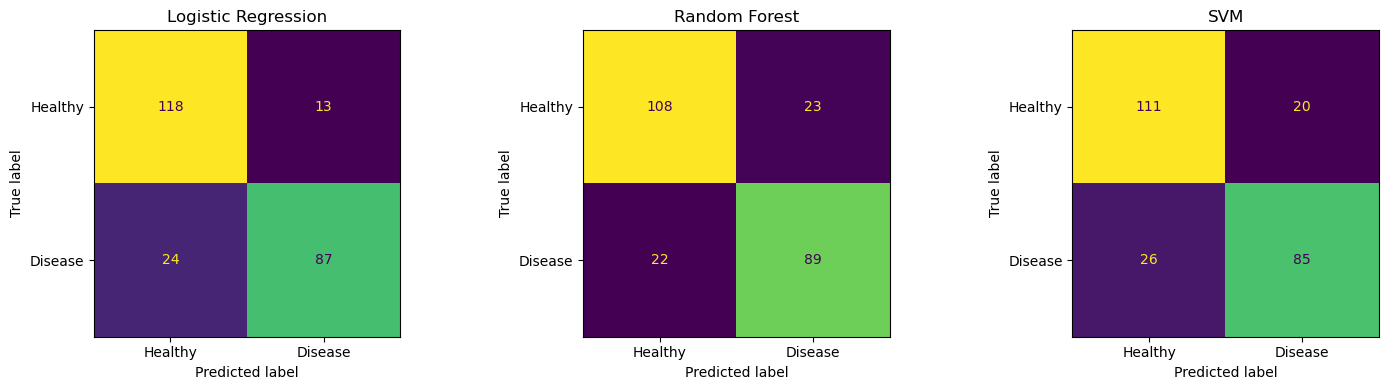

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, oof.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_train, (p >= 0.5).astype(int),
        display_labels=["Healthy", "Disease"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

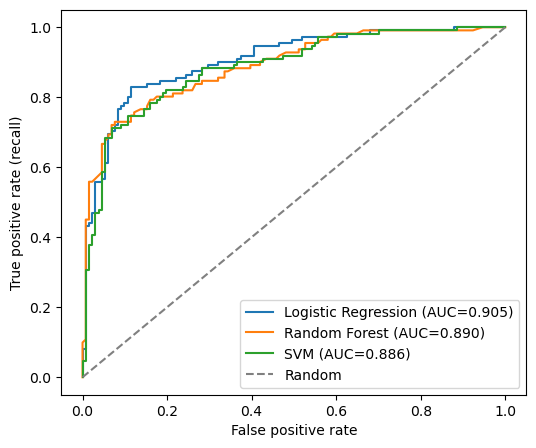

In [27]:
plt.figure(figsize=(6, 5))
for name, p in oof.items():
    fpr, tpr, _ = roc_curve(y_train, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_train, p):.3f})")
plt.plot([0, 1], [0, 1], "--", c="gray", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.show()

In [28]:
best = top3[0]
p = oof[best]
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    print(f"آستانه {t}: recall={recall_score(y_train, pred):.3f}  "
          f"precision={precision_score(y_train, pred):.3f}  FN={fn}  FP={fp}")

آستانه 0.3: recall=0.883  precision=0.715  FN=13  FP=39
آستانه 0.4: recall=0.838  precision=0.809  FN=18  FP=22
آستانه 0.5: recall=0.784  precision=0.870  FN=24  FP=13
آستانه 0.6: recall=0.730  precision=0.880  FN=30  FP=11


In [29]:
from sklearn.model_selection import GridSearchCV

grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [3, 5, None],
        "model__min_samples_leaf": [1, 3],
    },
}

In [30]:
searches = {}
for name, grid in grids.items():
    gs = GridSearchCV(pipelines[name], grid, cv=cv,
                      scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name}: AUC={gs.best_score_:.3f}  بهترین پارامترها={gs.best_params_}")

Logistic Regression: AUC=0.902  بهترین پارامترها={'model__C': 1}
SVM: AUC=0.897  بهترین پارامترها={'model__C': 10, 'model__gamma': 0.01}
Random Forest: AUC=0.904  بهترین پارامترها={'model__max_depth': 5, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}


In [31]:
before = results.set_index("model")["AUC"]
rows = []
for name, gs in searches.items():
    rows.append({"model": name,
                 "AUC_before": before[name],
                 "AUC_tuned": gs.best_score_})
pd.DataFrame(rows).round(3)

,model,AUC_before,AUC_tuned
0,Logistic Regression,0.902,0.902
1,SVM,0.888,0.897
2,Random Forest,0.894,0.904


In [32]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print("مدل نهایی:", best_name)

p_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= 0.5).astype(int)

print("AUC     :", round(roc_auc_score(y_test, p_test), 3))
print("recall  :", round(recall_score(y_test, pred_test), 3))
print("precision:", round(precision_score(y_test, pred_test), 3))
print(confusion_matrix(y_test, pred_test))

مدل نهایی: Random Forest
AUC     : 0.955
recall  : 0.893
precision: 0.806
[[27  6]
 [ 3 25]]
